# 1D Diffusion Equation: Implicit BTCS Scheme

**References:** `Notes/Tutorial_03_11_26.pptx`, `Notes/problem_set_III.pdf` (Q5), `Notes/Quiz2/02_1D_Diffusion_Implicit_BTCS.ipynb`

## Concept, Formulas & Stability
The **Backward Time Centered Space (BTCS)** scheme uses the unknown future values at $t_{n+1}$:
$$-C\rho_{i-1}^{n+1} + (1 + 2C)\rho_i^{n+1} - C\rho_{i+1}^{n+1} = \rho_i^n, \qquad C = \frac{D\Delta t}{\Delta x^2}$$

- **Tridiagonal Matrix Form:** $A\,\rho^{n+1} = \rho^n$, where $A$ has $(1+2C)$ on the main diagonal and $-C$ on the first upper and lower diagonals.
- **Stability Condition (von Neumann):**
  $$G(k) = \frac{1}{1 + 4C \sin^2(k\Delta x / 2)} \le 1 \quad \text{for ALL } \Delta t > 0$$
  So BTCS is **unconditionally stable** (never blows up even if $C \gg 0.5$).
- **Limitations:** Requires solving a linear system at every time step, and very large $\Delta t$ reduces time accuracy even though it stays stable.

*Professor code: None provided separately for BTCS (this matches the Quiz 2 Reference code).*

Implicit BTCS Courant number C = 2.222 (Unconditionally stable)


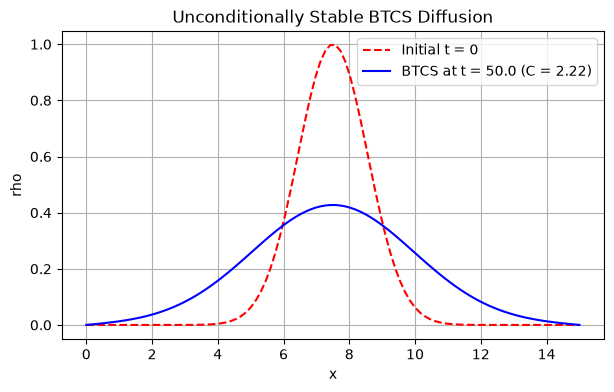

In [1]:
import numpy as np
import scipy.linalg as la
import matplotlib.pyplot as plt

N = 100
dx = 0.15
L = N * dx
D = 0.05
dt = 1.0              # Large step: C = 2.22 >> 0.5 (FTCS would blow up!)
C = D * dt / (dx**2)
print(f"Implicit BTCS Courant number C = {C:.3f} (Unconditionally stable)")

x = np.linspace(0, L, N)
rho = np.exp(-((x - L/2) / 1.5)**2)
rho_0 = rho.copy()

# Build Tridiagonal Matrix A
main_diag = (1 + 2 * C) * np.ones(N)
off_diag = -C * np.ones(N - 1)
A = np.diag(main_diag) + np.diag(off_diag, -1) + np.diag(off_diag, 1)

# Dirichlet BCs on matrix A: rho[0] = 0, rho[N-1] = 0
A[0, :] = 0; A[0, 0] = 1.0
A[-1, :] = 0; A[-1, -1] = 1.0

for step in range(50):
    rhs = rho.copy()
    rhs[0] = 0.0
    rhs[-1] = 0.0
    rho = la.solve(A, rhs)

plt.figure(figsize=(7, 4))
plt.plot(x, rho_0, 'r--', label='Initial t = 0')
plt.plot(x, rho, 'b-', label=f'BTCS at t = {50*dt:.1f} (C = {C:.2f})')
plt.title('Unconditionally Stable BTCS Diffusion')
plt.xlabel('x'); plt.ylabel('rho')
plt.legend(); plt.grid(True)
plt.show()

---
## Exam Note: Solving $A\rho^{n+1} = b$ Without `scipy.linalg.solve` (Premid Fallback)
If a question asks not to use `scipy.linalg.solve` or `np.linalg.solve`, replace `la.solve(A, rhs)` with the standard **Gaussian elimination with partial pivoting** loop from Premid (`Notes/premid/LU.ipynb` or `Notes/Newton_SOE.ipynb`).